<a href="https://colab.research.google.com/github/simonpogo/AI/blob/main/ML_studenti_navade_K_means.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Nenadzorovano učenje (Segmentacija študentov)

Da bi resnično razumeli moč **nenadzorovanega učenja**, si poglejmo primer, kjer nimamo vnaprej določenih ocen ali ciljnih razredov.

Predstavljajte si, da imate podatke o **150 študentih** in dveh njihovih navadah:
1. **Ure študija na teden** (npr. od 0 do 40 ur)
2. **Ure družabnih aktivnosti na teden** (npr. zabave, šport, druženje; od 0 do 40 ur)

Naš cilj je uporabiti algoritem **K-Means**, da samodejno prepozna različne profile oz. tipe študentov na fakulteti, ne da bi mu mi vnaprej povedali, kakšni profili sploh obstajajo.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

# 1. Generiramo umetne, a realistične podatke za 3 skupine študentov
np.random.seed(42)

# Skupina A: Veliko študija, malo družabnega življenja ("Zagnani")
study_A = np.random.normal(32, 4, 50)
social_A = np.random.normal(8, 3, 50)

# Skupina B: Malo študija, veliko družabnega življenja ("Družabni")
study_B = np.random.normal(10, 3, 50)
social_B = np.random.normal(30, 4, 50)

# Skupina C: Uravnoteženi študenti ("Uravnoteženi")
study_C = np.random.normal(20, 4, 50)
social_C = np.random.normal(20, 4, 50)

# Združimo podatke
study_hours = np.concatenate([study_A, study_B, study_C])
social_hours = np.concatenate([social_A, social_B, social_C])

# Ustvarimo DataFrame (opazite, da nimamo nobenih oznak o skupinah!)
df_students = pd.DataFrame(
    {"Ure_studija": study_hours, "Ure_druzenja": social_hours}
)

# Prikažemo nekaj naključnih vrstic
print("Primer podatkov, ki jih vidi algoritem (brez kakršnihkoli oznak):")
display(df_students.sample(10, random_state=42))

Primer podatkov, ki jih vidi algoritem (brez kakršnihkoli oznak):


,Ure_studija,Ure_druzenja
73,5.794447,31.364608
18,28.367904,9.084908
118,18.058546,18.239822
78,10.298954,28.941373
76,7.028391,30.052008
31,39.409113,9.071338
64,9.422917,33.853505
141,19.541054,18.027996
68,13.428468,29.018448
82,6.813089,25.716430


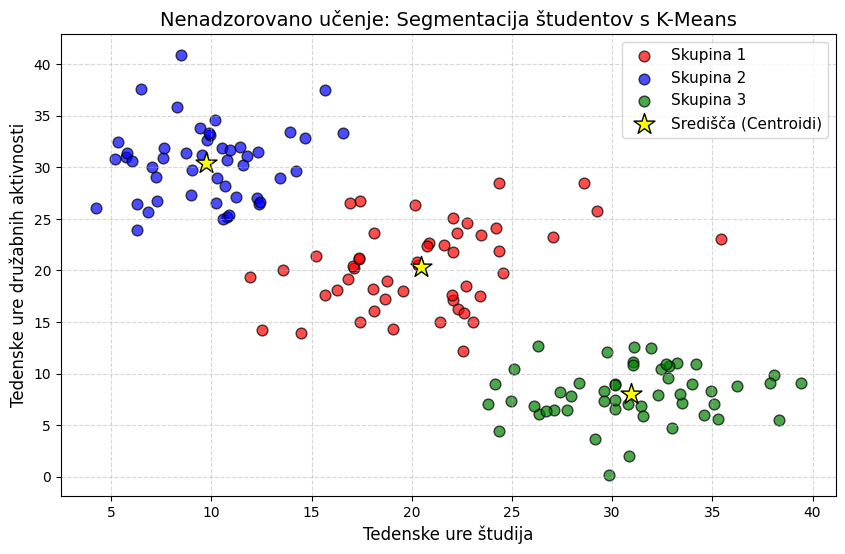

In [ ]:
# 2. Uporabimo K-Means za iskanje 3 skupin (K=3) na prvotnih dveh stolpcih
kmeans_students = KMeans(n_clusters=3, random_state=42, n_init=10)
# Model naučimo samo na stolpcih z značilnostmi (brez dodanega stolpca Skupina)
df_students["Skupina"] = kmeans_students.fit_predict(df_students[["Ure_studija", "Ure_druzenja"]])

# Center vsake skupine (centroidi)
centers = kmeans_students.cluster_centers_

# 3. Vizualizacija odkritih skupin
plt.figure(figsize=(10, 6))
colors = ["red", "blue", "green"]
labels = ["Skupina 1", "Skupina 2", "Skupina 3"]

for i in range(3):
    cluster_data = df_students[df_students["Skupina"] == i]
    plt.scatter(
        cluster_data["Ure_studija"],
        cluster_data["Ure_druzenja"],
        c=colors[i],
        label=labels[i],
        edgecolors="k",
        alpha=0.7,
        s=60,
    )

# Izris središč skupin (centroidov)
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c="yellow",
    s=250,
    marker="*",
    edgecolors="black",
    label="Središča (Centroidi)",
)

plt.title("Nenadzorovano učenje: Segmentacija študentov s K-Means", fontsize=14)
plt.xlabel("Tedenske ure študija", fontsize=12)
plt.ylabel("Tedenske ure družabnih aktivnosti", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(fontsize=11)
plt.show()

## Kako si razložimo te rezultate?

1. **Algoritem je delal 'na slepo'**: K-Means ni vnaprej vedel, da obstajajo trije tipi študentov. Samostojno je analiziral razdalje med točkami in združil tiste, ki so si najbolj podobni.
2. **Kaj pomenijo te skupine?** (Interpretacija rezultatov):
   * **Rdeča/Zelena/Modra skupina** (odvisno od naključne dodelitve barv): Jasno vidimo ločene skupine. Ena predstavlja študente z visoko stopnjo študija in malo druženja (*akademsko usmerjeni*), druga predstavlja tiste z veliko druženja (*družabno usmerjeni*), tretja pa tiste v sredini (*uravnoteženi*).
3. **Uporaba v realnem svetu**: Podjetja uporabljajo enak princip za segmentacijo kupcev (npr. Netflix za iskanje skupin uporabnikov s podobnim okusom za filme, ne da bi vnaprej določil žanre).


### Napovedovanje skupine za novega študenta
V spodnji celici lahko z drsniki izberete tedensko število ur študija in družabnih aktivnosti za novega študenta. Algoritem bo samodejno izračunal, kateremu centroidu (središču skupine) je ta študent najbližje, in vam vrnil napoved.

In [ ]:
# @title Vnesite podatke o novem študentu { run: "auto" }
ure_studija = 3 #@param {type:"slider", min:0, max:40, step:1}
ure_druzenja = 5 #@param {type:"slider", min:0, max:40, step:1}

# Pripravimo podatke kot DataFrame z enakimi imeni stolpcev, da se izognemo opozorilom
nov_student = pd.DataFrame(
    [[ure_studija, ure_druzenja]],
    columns=["Ure_studija", "Ure_druzenja"]
)

# K-means napoved (vrne indeks skupine: 0, 1 ali 2)
napovedana_skupina_idx = kmeans_students.predict(nov_student)[0]

# Dinamično določimo poimenovanja na podlagi lokacije centroidov za večjo natančnost
imena_skupin = {}
for idx, center in enumerate(centers):
    u_stud, u_druz = center[0], center[1]
    if u_stud > 25 and u_druz < 15:
        imena_skupin[idx] = f"Skupina {idx + 1} (Piflar)"
    elif u_stud < 15 and u_druz > 25:
        imena_skupin[idx] = f"Skupina {idx + 1} (Žurer)"
    else:
        imena_skupin[idx] = f"Skupina {idx + 1} (Uravnotežen)"

izbrana_skupina = imena_skupin.get(napovedana_skupina_idx, f"Skupina {napovedana_skupina_idx}")

# Uporabimo HTML za večji in lepši izpis rezultatov s temnim ozadjem in svetlim besedilom
from IPython.display import HTML, display

html_output = f"""
<div style="border: 2px solid #388E3C; padding: 15px; border-radius: 8px; background-color: #1e1e1e; font-family: sans-serif; color: #ffffff;">
  <h3 style="color: #4CAF50; margin-top: 0; font-size: 20px;">Rezultat klasifikacije</h3>
  <p style="font-size: 16px; margin: 5px 0; color: #e0e0e0;"><b>Vneseni podatki:</b> {ure_studija} ur študija, {ure_druzenja} ur druženja</p>
  <p style="font-size: 22px; margin: 12px 0 0 0; color: #ffffff;"><b>Napovedana skupina:</b> <span style="background-color: #2e7d32; color: #ffffff; padding: 4px 10px; border-radius: 4px; font-weight: bold;">{izbrana_skupina}</span></p>
</div>
"""

display(HTML(html_output))